# Module 6: Forward Equation, Barriers, Greeks and Risk-Neutral Pricing, Tested on Real Data

*By Héctor Ornelas*

Module 5 solved one equation for one option. This module widens the toolkit around it: it looks at all
the paths at once, adds barriers that a price cannot cross, measures how sensitive an option is to its
inputs, deals with early exercise, prices by simulation, and extends Itô's lemma to several variables.
As before, I take the eight topics of the course in the same order and test each one with real data.

The rules are the same as in Module 1: same topics as the course, real data from a Mexican point of
view, and every formula written by hand. Most of this module uses the peso and the SPY, because barriers
and options are where the exchange rate becomes a practical question for a Mexican.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import erf, exp, log, pi, sqrt

# fix the seed so every run gives exactly the same numbers
np.random.seed(37)

# one common style for all the plots: size, a light grid, and font size
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})

def Phi(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

def phi(x):
    return exp(-x * x / 2) / sqrt(2 * pi)

def d1d2(S, K, T, r, sig):
    d1 = (log(S / K) + (r + sig**2 / 2) * T) / (sig * sqrt(T))
    return d1, d1 - sig * sqrt(T)

def bs_call(S, K, T, r, sig):
    d1, d2 = d1d2(S, K, T, r, sig)
    return S * Phi(d1) - K * exp(-r * T) * Phi(d2)

prices = pd.read_csv("data/prices.csv", index_col=0, parse_dates=True)
rates = pd.read_csv("data/rates.csv", index_col=0, parse_dates=True)

spy = pd.concat([prices[["SPY", "VIX", "USDMXN"]], rates["US3M"]], axis=1, sort=True).ffill()
spy = spy[spy.index.isin(prices["SPY"].dropna().index)].dropna()

fx = prices["USDMXN"].dropna()
lfx = np.log(fx.values)
S0_fx = fx.iloc[-1]

## 1. The ensemble view: the forward equation

Instead of following one path, the **forward (Fokker-Planck) equation** describes the distribution of
all paths at a given time. For a process with constant drift $\mu$ and volatility $\sigma$,

$$\frac{\partial p}{\partial t} = -\mu\frac{\partial p}{\partial x} + \frac12\sigma^2\frac{\partial^2 p}{\partial x^2},$$

and its solution is a Gaussian whose center moves at speed $\mu$ and whose width grows like
$\sigma\sqrt{t}$.

**Exercise 1. The peso from every starting day.** I take every change in the log of USD/MXN over 21,
63, 126 and 252 days in the history, and compare their mean and width with $\mu t$ and $\sigma\sqrt{t}$.

USD/MXN today 18.40   daily drift +0.00009   daily vol 0.0074

 days  real mean     mu t  real std  sigma sqrt(t)
   21     0.0017   0.0019    0.0346         0.0339
   63     0.0051   0.0057    0.0595         0.0587
  126     0.0106   0.0114    0.0823         0.0830
  252     0.0233   0.0229    0.1081         0.1174

independent years: 21.7   standard error of the one-year std: 0.016
one-year std with non-overlapping years, by starting month: 0.095 to 0.135


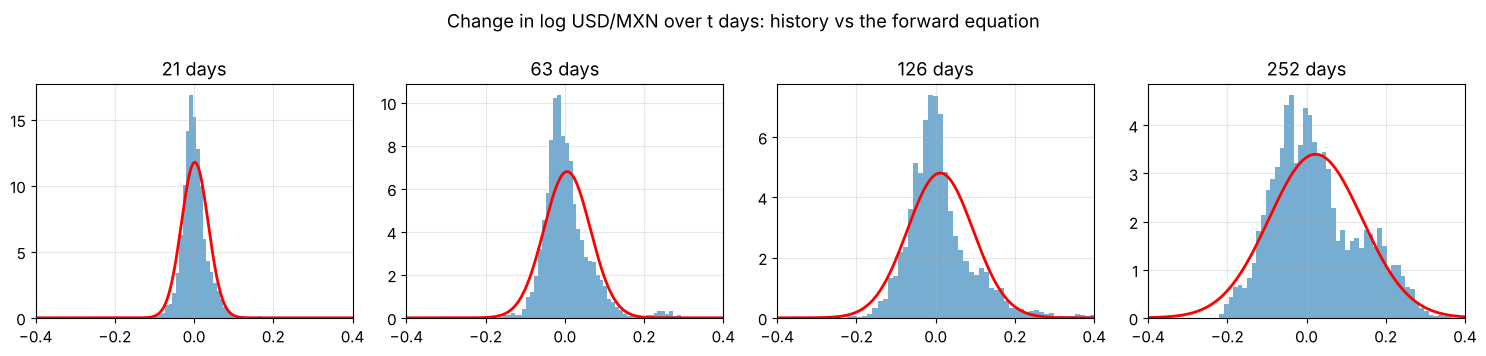

In [2]:
r_fx = np.diff(lfx)
mu_d, sig_d = r_fx.mean(), r_fx.std()
print(f"USD/MXN today {S0_fx:.2f}   daily drift {mu_d:+.5f}   daily vol {sig_d:.4f}\n")
print(f"{'days':>5}{'real mean':>11}{'mu t':>9}{'real std':>10}{'sigma sqrt(t)':>15}")

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, h in zip(ax, [21, 63, 126, 252]):
    x = lfx[h:] - lfx[:-h]                           # every h-day change in the history
    print(f"{h:>5}{x.mean():>11.4f}{mu_d * h:>9.4f}{x.std():>10.4f}{sig_d * sqrt(h):>15.4f}")
    grid = np.linspace(-0.4, 0.4, 300)
    m, s = mu_d * h, sig_d * sqrt(h)
    a.hist(x, bins=50, density=True, alpha=0.6)
    a.plot(grid, np.exp(-(grid - m)**2 / (2 * s**2)) / (s * sqrt(2 * pi)), color="red", lw=2)
    a.set_xlim(-0.4, 0.4); a.set_title(f"{h} days")
# the one-year windows overlap, so there are only about 21 independent years behind the last row
n_years = len(lfx) / 252
x = lfx[252:] - lfx[:-252]
yearly = [np.std(np.diff(lfx[o::252])) for o in range(0, 252, 21)]
print(f"\nindependent years: {n_years:.1f}   standard error of the one-year std: {x.std() / sqrt(2 * n_years):.3f}")
print(f"one-year std with non-overlapping years, by starting month: {min(yearly):.3f} to {max(yearly):.3f}")
plt.suptitle("Change in log USD/MXN over t days: history vs the forward equation"); plt.tight_layout(); plt.show()

The center moves as the equation says: the average change over a year was 0.0233 against
$\mu t = 0.0229$, and the width at one month and one quarter is almost exactly $\sigma\sqrt{t}$. At one
year the real width is a bit smaller, 0.108 against 0.117, but this gap is not clear. The one-year
windows overlap, so behind that row there are only about 21 independent years, and the standard error of
the width is 0.016, larger than the gap. With years that do not overlap, the width goes from 0.095 to
0.135 depending on the starting month. So the forward equation describes the cloud of peso paths well,
and the data cannot separate the one-year gap from noise, as in Module 2, where the peso did not reject
the random walk.

## 2. Boundaries and the method of images

Many practical questions are about a barrier, for example: will the dollar touch 20 pesos at some point
this year? Counting the paths that touch a barrier is hard, but the **method of images** solves it with
a symmetry. Without drift, every path that touches the barrier and ends below it has a mirror path that
ends above it, so

$$P(\text{touch } b \text{ before } T) = 2\,P(\text{end above } b).$$

**Exercise 2. Will the dollar touch 20 pesos within a year?** From today's 18.40 pesos per dollar, 20
pesos is a move of $+8.34\%$. I compute the probability with the no-drift formula, and in the history I
check, from every starting day, if the dollar touched a move of that size within a year and if it ended
above it.

In [3]:
b = log(20 / S0_fx)              # the barrier: the dollar at 20 pesos, measured from today
H = 252
sig_y = sig_d * sqrt(H)

# history: from every starting day, does the dollar touch +b within a year, and does it end above +b?
touch, end = [], []
for i in range(len(lfx) - H):
    path = lfx[i + 1:i + H + 1] - lfx[i]
    touch.append(path.max() >= b)
    end.append(path[-1] >= b)
touch, end = np.mean(touch), np.mean(end)

p_end = 1 - Phi(b / sig_y)                        # no drift: P(end above b)
print(f"barrier: +{b:.2%} (20 pesos from {S0_fx:.2f}), horizon one year")
print(f"no-drift formula:  P(end above) = {p_end:.1%}   P(touch) = 2 x P(end above) = {2 * p_end:.1%}")
print(f"history:           P(end above) = {end:.1%}   P(touch) = {touch:.1%}   ratio = {touch / end:.2f}")

# the history only checks the barrier once a day; the usual correction moves the barrier up by 0.5826 daily vols
b_daily = b + 0.5826 * sig_d
print(f"no-drift formula, checked once a day: P(touch) = {2 * (1 - Phi(b_daily / sig_y)):.1%}")
n_years = (len(lfx) - H) / H + 1
print(f"independent years: {n_years:.1f}   standard error: P(touch) {sqrt(touch * (1 - touch) / n_years):.1%}"
      f"   P(end above) {sqrt(end * (1 - end) / n_years):.1%}")

barrier: +8.34% (20 pesos from 18.40), horizon one year
no-drift formula:  P(end above) = 23.9%   P(touch) = 2 x P(end above) = 47.7%
history:           P(end above) = 26.7%   P(touch) = 45.9%   ratio = 1.72
no-drift formula, checked once a day: P(touch) = 45.5%
independent years: 21.7   standard error: P(touch) 10.7%   P(end above) 9.5%


The no-drift formula says that the dollar ends above 20 pesos with a probability of 23.9% and touches
20 pesos at some point with 47.7%, twice as much. The history gives 26.7% and 45.9%, very close. So
almost one year in two, the dollar touches a level it does not keep at the end of the year. For a
company or a person who has to buy dollars, this is why the moment of the purchase matters, and why the
end-of-year number alone hides part of the risk. In the history the ratio is 1.72 instead of 2, and
part of that gap has a simple reason: the formula assumes that the price is watched all the time, and
the history only checks it once a day, so it misses some touches inside the day. With the usual
correction for checking once a day, the formula gives 45.5%, almost the same as the 45.9% of the
history. These comparisons also have a limit. The windows overlap, so there are about 21 independent
years, and the standard error is around 10 points for both probabilities.

## 3. Adding drift: reweighting the image

With drift the symmetry breaks, but a weighted image still works. For a drift $\mu$ over a horizon $T$,

$$P(\text{touch } b) = \Phi\!\left(\frac{-b+\mu T}{\sigma\sqrt T}\right) + e^{2\mu b/\sigma^2}\,
\Phi\!\left(\frac{-b-\mu T}{\sigma\sqrt T}\right).$$

**Exercise 3. The same question with the peso's drift.** The dollar has gained against the peso on
average over these 21 years, so I repeat the calculation with that drift.

In [4]:
mu_y = mu_d * H
p_end_d = 1 - Phi((b - mu_y) / sig_y)
p_touch_d = 1 - Phi((b - mu_y) / sig_y) + exp(2 * mu_y * b / sig_y**2) * (1 - Phi((b + mu_y) / sig_y))
print(f"drift of the peso: {mu_y:+.2%} per year (the dollar has gained against the peso on average)")
print(f"formula with drift:  P(end above) = {p_end_d:.1%}   P(touch) = {p_touch_d:.1%}")
print(f"history:             P(end above) = {end:.1%}   P(touch) = {touch:.1%}")

drift of the peso: +2.29% per year (the dollar has gained against the peso on average)
formula with drift:  P(end above) = 30.3%   P(touch) = 54.4%
history:             P(end above) = 26.7%   P(touch) = 45.9%


With the drift of $+2.29\%$ per year, the formula gives 30.3% for ending above 20 pesos and 54.4% for
touching it, and both numbers are now further from the history (26.7% and 45.9%) than the no-drift
version. With a standard error of around 10 points, the history cannot really choose between the two
versions, but adding the drift did not make the answer better. The formula is right, the problem is the
input. Module 3 showed that a mean return cannot be estimated well with 21 years of data, and the drift
of the peso is no exception, so adding it brings more uncertainty than information.

## 4. The Greeks: sensitivities of the solution

With a formula for the price, its derivatives are easy to compute, and risk management works with
them:

$$\Delta = \Phi(d_1), \qquad \Gamma = \frac{\varphi(d_1)}{S\sigma\sqrt{\tau}}, \qquad
\mathcal{V} = S\varphi(d_1)\sqrt{\tau}.$$

$\Delta$ is the hedge ratio, $\Gamma$ says how fast $\Delta$ changes, and vega is the sensitivity to
volatility. A common approximation for a small move $dS$ is
$dV \approx \Delta\,dS + \tfrac12\Gamma\,dS^2$.

**Exercise 4. Greeks by market regime, and the limit of the approximation.** For every month I compute
the Greeks of a one-month at-the-money SPY call and group them by the level of the VIX. Then I check the
approximation for three moves, including $-11.5\%$, about the size of the worst SPY day in the data.

In [5]:
# Greeks of a one-month at-the-money SPY call at the start of each month, with the VIX as volatility
rows = []
for per, g in spy.groupby(spy.index.to_period("M")):
    if len(g) < 18:
        continue
    S, sig, rate, T = g["SPY"].iloc[0], g["VIX"].iloc[0] / 100, g["US3M"].iloc[0] / 100, (len(g) - 1) / 252
    d1, d2 = d1d2(S, S, T, rate, sig)
    gamma_1pct = phi(d1) / (S * sig * sqrt(T)) * S / 100          # change in delta after a 1% move
    rows.append([per, sig, Phi(d1), gamma_1pct, bs_call(S, S, T, rate, sig) / S])
gk = pd.DataFrame(rows, columns=["month", "VIX", "delta", "delta change per 1% move", "price (% of S)"]).set_index("month")
gk["VIX level"] = pd.cut(gk["VIX"], [0, 0.15, 0.25, 1.0], labels=["calm (<15)", "normal (15-25)", "stressed (>25)"])
print(gk.groupby("VIX level", observed=True)[["delta", "delta change per 1% move", "price (% of S)"]].mean().round(4).to_string())
print(gk["VIX level"].value_counts().sort_index().to_string())

# but calm months also have smaller moves: how much does delta really change in a day, by regime?
daily = []
for per, g in spy.groupby(spy.index.to_period("M")):
    if len(g) < 18:
        continue
    S, sig, rate, n = g["SPY"].values, g["VIX"].iloc[0] / 100, g["US3M"].iloc[0] / 100, len(g) - 1
    deltas = [Phi(d1d2(S[i], S[0], (n - i) / 252, rate, sig)[0]) for i in range(10)]
    daily.append(np.mean(np.abs(np.diff(deltas))))          # first two weeks, while the call is near the money
gk["daily delta change"] = daily
print("\naverage daily change of delta in the first two weeks:")
print(gk.groupby("VIX level", observed=True)["daily delta change"].mean().round(3).to_string())

# how good is the Taylor approximation on a normal day and on the worst day?
K, T, sig, rate = 100.0, 21 / 252, 0.20, 0.03
d1, _ = d1d2(100, K, T, rate, sig)
delta, gamma = Phi(d1), phi(d1) / (100 * sig * sqrt(T))
print("\none-month call at 100, vol 20%:  change in price after a move of the stock")
print(f"{'move':>7}{'real':>8}{'delta only':>12}{'delta+gamma':>13}")
for move in [0.01, -0.03, -0.115]:
    S1 = 100 * (1 + move)
    real = bs_call(S1, K, T, rate, sig) - bs_call(100, K, T, rate, sig)
    dS = S1 - 100
    print(f"{move:>+7.1%}{real:>8.2f}{delta * dS:>12.2f}{delta * dS + 0.5 * gamma * dS**2:>13.2f}")

                 delta  delta change per 1% move  price (% of S)
VIX level                                                       
calm (<15)      0.5271                    0.1117          0.0153
normal (15-25)  0.5218                    0.0760          0.0221
stressed (>25)  0.5212                    0.0439          0.0386
VIX level
calm (<15)         93
normal (15-25)    127
stressed (>25)     41

average daily change of delta in the first two weeks:
VIX level
calm (<15)        0.054
normal (15-25)    0.056
stressed (>25)    0.062

one-month call at 100, vol 20%:  change in price after a move of the stock
   move    real  delta only  delta+gamma
  +1.0%    0.56        0.53         0.56
  -3.0%   -1.28       -1.59        -1.28
 -11.5%   -2.39       -6.08        -1.52


In calm months (VIX below 15) the delta of the call changes by 0.11 after a 1% move, and in stressed
months (VIX above 25) only by 0.04, while the option is two and a half times more expensive (3.9% of the
SPY against 1.5%). But this does not mean that the hedge needs more rebalancing in calm markets,
because in calm months the daily moves are also smaller. The average daily change of delta in the first
two weeks was almost the same in the three regimes, 0.054, 0.056 and 0.062. This matches the theory: for
an at-the-money option, gamma times a typical daily move does not depend on the volatility. What does
change with the regime is the price, so in stressed markets protection costs more. The second table shows the limit of the approximation. For a
1% move, delta plus gamma is almost exact (0.56). For a $-3\%$ move it is still exact, and delta alone
is already off by about 24%. For a crash of $-11.5\%$ both fail: the call loses 2.39, delta alone says 6.08,
and delta plus gamma says 1.52. On the days that matter most, the Greeks are only a rough guide.

## 5. The binary option and a warning about probabilities

A **binary** call pays 1 if the stock ends above $K$. Its Black-Scholes price is $e^{-r\tau}\Phi(d_2)$,
so it is tempting to read $\Phi(d_2)$ as "the probability that the stock ends above $K$". That is wrong:
$\Phi(d_2)$ is a probability under the **risk-neutral** measure, where every asset grows at $r$, and
not under the real one.

**Exercise 5. Risk-neutral against real probability.** For every month, I compute $\Phi(d_2)$ for a
binary that pays if the SPY ends the month above its starting level, using the VIX, and I compare it
with the share of months the SPY really went up.

In [6]:
# a binary call pays 1 if SPY ends the month above its starting level; its price is exp(-rT) * Phi(d2)
rows = []
for per, g in spy.groupby(spy.index.to_period("M")):
    if len(g) < 18:
        continue
    S, sig, rate, T = g["SPY"].values, g["VIX"].iloc[0] / 100, g["US3M"].iloc[0] / 100, (len(g) - 1) / 252
    _, d2 = d1d2(S[0], S[0], T, rate, sig)
    rows.append([Phi(d2), S[-1] > S[0]])
bn = pd.DataFrame(rows, columns=["Phi(d2)", "up"])
print(f"{len(bn)} months")
print(f"average risk-neutral probability Phi(d2): {bn['Phi(d2)'].mean():.1%}")
print(f"share of months the SPY really went up   : {bn['up'].mean():.1%}")
print(f"standard error of that share             : {sqrt(bn['up'].mean() * (1 - bn['up'].mean()) / len(bn)):.1%}")

261 months
average risk-neutral probability Phi(d2): 50.2%
share of months the SPY really went up   : 65.1%
standard error of that share             : 2.9%


The risk-neutral probability was 50.2% on average, while the SPY went up in 65.1% of the months. The
difference is about 15 points, and the standard error of the real share is 2.9 points, so the gap is
real and not noise. It does not mean the market priced options wrong. It means that $\Phi(d_2)$
answers a different question: it is the price of the bet, and it includes what investors pay to avoid
risk. Reading it as a forecast would have underestimated how often the market goes up by around 15
points.

## 6. Early exercise: the perpetual American put

An American option can be exercised at any time. For a put with no expiry, the best strategy is to
exercise when the price falls to a level $S^*$, and the solution has a closed form:

$$S^* = \frac{\gamma}{1+\gamma}K, \qquad \gamma = \frac{2r}{\sigma^2}.$$

So the decision depends on the interest rate: exercising early gives cash that earns $r$, and waiting
keeps the chance that the price falls more.

**Exercise 6. When to exercise, through 21 years of rates.** For every month I compute $S^*/K$ for the
SPY, using the US 3-month rate and the VIX.

2007-06:  rate  4.68%   VIX  16.2   exercise when S falls to 78% of K
2009-12:  rate  0.06%   VIX  21.7   exercise when S falls to 2% of K
2014-06:  rate  0.04%   VIX  11.6   exercise when S falls to 6% of K
2020-04:  rate  0.09%   VIX  34.2   exercise when S falls to 2% of K
2023-10:  rate  5.33%   VIX  18.1   exercise when S falls to 76% of K
2026-09:  rate  4.03%   VIX  16.3   exercise when S falls to 75% of K


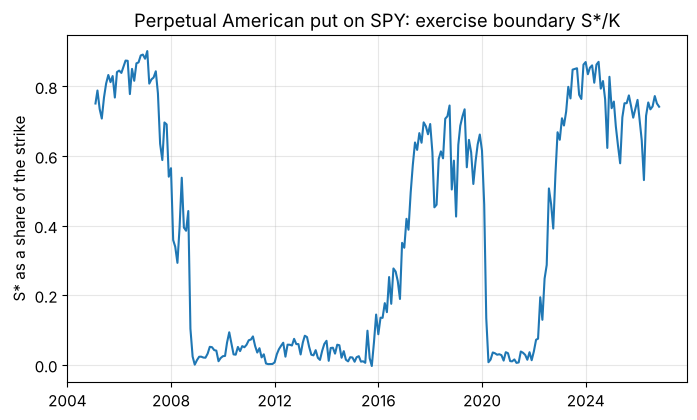

In [7]:
# perpetual American put: exercise when S falls to S* = K * gamma / (1 + gamma), with gamma = 2r / sigma^2
m = spy.resample("ME").last()
gam = 2 * (m["US3M"] / 100) / (m["VIX"] / 100)**2
m["S*/K"] = gam / (1 + gam)
for d in ["2007-06", "2009-12", "2014-06", "2020-04", "2023-10", "2026-09"]:
    row = m.loc[d].iloc[0]
    print(f"{d}:  rate {row['US3M']:5.2f}%   VIX {row['VIX']:5.1f}   exercise when S falls to {row['S*/K']:.0%} of K")

plt.plot(m.index, m["S*/K"], lw=1.5)
plt.title("Perpetual American put on SPY: exercise boundary S*/K")
plt.ylabel("S* as a share of the strike"); plt.show()

The rate decides almost everything. In 2007 and 2023, with rates around 5%, the put should be exercised
when the SPY falls to about 75% to 78% of the strike. From 2009 to 2015 and in 2020, with rates near
zero, the boundary falls to 2% to 6% of the strike, which means never exercising in practice, because
cash earns nothing. So the same put, on the same stock, is a different decision depending on the
monetary policy of the moment. Two simplifications: the formula ignores the dividends of the SPY, which
would make exercising later more attractive, and a real put has an expiry date, while this one lasts
forever.

## 7. Monte Carlo pricing under the risk-neutral measure

The price can also be computed by simulation: replace the real drift $\mu$ by the risk-free rate $r$,
simulate many final prices, average the payoff and discount it:

$$V = e^{-r\tau}\,\mathbb{E}^{Q}\!\left[\max(S_T - K, 0)\right].$$

**Exercise 7. Simulating today's SPY call.** I price a one-month at-the-money SPY call with 200,000
simulated paths, first with $\mu = r$ (risk-neutral) and then with the historical drift of the SPY, and
compare both with the formula.

In [8]:
S0, sig0, r0 = spy["SPY"].iloc[-1], spy["VIX"].iloc[-1] / 100, spy["US3M"].iloc[-1] / 100
T0, K = 21 / 252, spy["SPY"].iloc[-1]
mu_hist = np.log(prices["SPY"].dropna()).diff().mean() * 252 + 0.5 * sig0**2   # historical drift of SPY

z = np.random.normal(size=200_000)
for name, drift in [("risk-neutral (mu = r)", r0), ("real-world (mu = history)", mu_hist)]:
    ST = S0 * np.exp((drift - sig0**2 / 2) * T0 + sig0 * sqrt(T0) * z)
    pay = np.exp(-r0 * T0) * np.maximum(ST - K, 0)
    print(f"{name:<27} drift {drift:6.2%}   Monte Carlo {pay.mean():.3f} +/- {2 * pay.std() / sqrt(len(z)):.3f}")
print(f"{'Black-Scholes formula':<27} {'':14} {bs_call(S0, K, T0, r0, sig0):.3f}")

risk-neutral (mu = r)       drift  4.09%   Monte Carlo 16.189 +/- 0.105
real-world (mu = history)   drift 11.78%   Monte Carlo 18.972 +/- 0.113
Black-Scholes formula                      16.271


With $\mu = r$ the simulation gives 16.19, within its error of $\pm 0.11$ of the formula's 16.27. With
the historical drift of 11.8% per year it gives 18.97, about 17% more. That second number is not a
price: anyone could sell the call at 16.27, hedge it as in Module 4, and the expected return of the SPY
would not matter. This is the same lesson as Section 5, the probability used for pricing is not the
probability of what will happen.

## 8. Itô's lemma with several correlated variables

With several Itô processes whose Brownian motions are correlated, $dB_i\,dB_j = \rho_{ij}\,dt$. For a
product $F = XY$ this gives

$$\frac{dF}{F} = \frac{dX}{X} + \frac{dY}{Y} + \rho\,\sigma_X\sigma_Y\,dt,$$

so the expected return of a product has an extra covariance term. The SPY in pesos is exactly this
product: the SPY in dollars times the dollar in pesos.

**Exercise 8. The return of the SPY in pesos.** With monthly data, I compare the mean return of the SPY
in pesos with the sum of the mean return of the SPY, the mean return of the dollar, and their
covariance.

In [9]:
# SPY in pesos is a product X * Y. Ito with two correlated processes:
# d(XY)/(XY) = dX/X + dY/Y + rho sigma_X sigma_Y dt, so the mean return of the product has an extra covariance term
x = prices[["SPY", "USDMXN"]].dropna().resample("ME").last()
x["SPY_MXN"] = x["SPY"] * x["USDMXN"]
R = x.pct_change().dropna()

cov = R["SPY"].cov(R["USDMXN"])
print(f"{len(R)} months")
print(f"mean monthly return SPY in dollars : {R['SPY'].mean():+.4%}")
print(f"mean monthly return of the dollar  : {R['USDMXN'].mean():+.4%}")
print(f"covariance term rho sX sY          : {cov:+.4%}")
print(f"sum (Ito with two variables)       : {R['SPY'].mean() + R['USDMXN'].mean() + cov:+.4%}")
print(f"real mean return of SPY in pesos   : {R['SPY_MXN'].mean():+.4%}")
print(f"difference                         : {R['SPY_MXN'].mean() - (R['SPY'].mean() + R['USDMXN'].mean() + cov):+.4%}")
print(f"product of the two means           : {R['SPY'].mean() * R['USDMXN'].mean():+.4%}")
print(f"\ncorrelation SPY vs USD/MXN (monthly): {R['SPY'].corr(R['USDMXN']):+.2f}")

261 months
mean monthly return SPY in dollars : +0.9696%
mean monthly return of the dollar  : +0.2432%
covariance term rho sX sY          : -0.0782%
sum (Ito with two variables)       : +1.1346%
real mean return of SPY in pesos   : +1.1372%
difference                         : +0.0027%
product of the two means           : +0.0024%

correlation SPY vs USD/MXN (monthly): -0.55


The SPY in dollars gave 0.970% per month, the dollar gained 0.243% against the peso, and the covariance
term is $-0.078\%$, so the sum is 1.135%, against a real 1.137%. This match should not be read as a
strong test. With monthly returns, $(1+a)(1+b) - 1 = a + b + ab$, so the mean of the product is almost
by algebra the sum of the means plus the covariance, and the small difference that remains, 0.0027%, is
mostly the product of the two means (0.0024%). What the data does show is the size and the sign of the
covariance term, which is the part that Itô's lemma adds. The covariance
term is negative because the SPY and the dollar move in opposite directions (correlation $-0.55$): the
same protection that lowered the risk in Modules 1 and 2 also lowers the expected return a little. For
a Mexican, holding US assets means holding two correlated variables, and Itô's lemma says exactly how
much each part contributes.

## Wrapping up Module 6

This module used the Black-Scholes solution as a tool for real questions. The forward equation and the
method of images describe the peso well: from today's 18.40, the dollar touches 20 pesos within a year
almost one time in two, while it ends there only one time in four. Adding the estimated drift did not
make the answer better, which is again the problem of estimating a mean.

The pricing results all point to the same idea. The risk-neutral probability of the SPY going up in a
month was 50%, while it really went up 65% of the time, and a Monte Carlo price with the real drift
was 17% too high. The Greeks are useful for normal moves and fail on crash days, and the decision to
exercise an American put depends mostly on the level of interest rates. Finally, Itô's lemma with two
variables shows how the return of the SPY measured in pesos splits into the SPY, the dollar, and a
negative covariance term between them.

The next step is Module 7, which changes tools completely and describes markets with linear algebra.